# <font color='#2E86C1' size=6>**Regression modelling: how much will a returning customer spend in the next 90 days?**</font>

**Workflow:** [01 Data cleaning](01_data_cleaning.ipynb) → [02 Customer table](02_customer_table.ipynb) → [03 Missing values](03_missing_values.ipynb) → [04 Outliers](04_outlier_detection.ipynb) → [05 Pipeline and models](05_pipeline_and_models.ipynb) → [06 Feature engineering and selection](06_feature_engineering_selection.ipynb) → [07 Classification modelling](07_classification_modelling.ipynb) → **08 Regression modelling**

**Scope.** Predict `spend_next_90d` in EUR for customers who return within the next 90 days. The target is observed only for repeat purchasers, so the regression population is conditional on returning.

| To-do | Section |
|---|---|
| Establish a mean-prediction baseline | 1 |
| Inspect the preprocessing pipeline | 2 |
| Compare candidate regressors | 3 |
| Hyperparameter tuning (Optuna, nested temporal CV) | 4 |
| Compare EUR-scale metrics | 5 |
| Select final model and evaluate locked test | 6 |
| Analyse residuals and spend bands | 7 |
| Feature importance and spend drivers | 8–9 |
| Summary and modelling decision | 10 |

**Rules.** Only rows selected by `regression.row_filter` with observed `spend_next_90d` are used. The target is never imputed. Predictions and metrics are in EUR, including when `target_transform: log1p` is used internally. Preprocessing is fitted inside each temporal fold. The locked test is not used for tuning or selection.

Paired fold differences are descriptive: temporal folds can be dependent, so fold standard deviations are not confidence intervals or significance tests. Project functions are imported rather than reimplemented.

<a class="anchor" id="toc"></a>
## Table of contents

0. [Setup](#setup)
1. [Baseline](#baseline)
2. [Preprocessing](#preprocessing)
3. [Candidate models](#candidates)
4. [Hyperparameter tuning](#tuning)
5. [Metric comparison](#comparison)
6. [Final model and locked test](#final)
7. [Residual analysis](#residuals)
8. [Feature importance](#importance)
9. [Spend drivers](#drivers)
10. [Summary](#summary)

# <font color='#2E86C1' size=6>**0. Setup**</font> <a class="anchor" id="setup"></a>

[Back to TOC](#toc)

In [1]:
import os, sys, time, warnings
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn, yaml
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, median_absolute_error, r2_score, root_mean_squared_error

from regression.preprocessing import select_training_rows, prepare_features
from regression.model import build_model
from regression.evaluate import SCORING, predict_for_report, regression_metrics, oof_report, holdout_report
from src.evaluate import cross_validate_with_oof, greater_is_better, paired_comparison, temporal_folds
from src.pipeline import build_pipeline, prepare_task_data
from src.tuning import nested_cross_validate, tune_pipeline

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)
sklearn.set_config(display="diagram")

with open("config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)
TASK = "regression"
task_cfg, data_cfg = config[TASK], config["data"]
DATE = data_cfg["date_column"]
SEED = config["preprocessing"].get("random_state", 42)
METRIC = task_cfg.get("selection_metric", "mae")
CURRENT_MODEL = task_cfg["model"]["type"]

# Same loading, validation, cleaning, history and locked split used by main.py.
data = prepare_task_data(config, TASK)
recipe = data["preprocessing_config"]
X_dev, X_test = data["X_dev"], data["X_test"]
y_dev, y_test = data["y_dev"], data["y_test"]
extras_dev, extras_test = data["extras_dev"], data["extras_test"]

# Retain only observed development targets; never impute y.
valid = pd.Series(y_dev).notna().to_numpy()
X_dev = X_dev.iloc[np.flatnonzero(valid)].reset_index(drop=True)
y_dev = pd.Series(y_dev).iloc[np.flatnonzero(valid)].astype(float).reset_index(drop=True)
extras_dev = extras_dev.iloc[np.flatnonzero(valid)].reset_index(drop=True)
folds = temporal_folds(extras_dev[DATE], config["cv"]["n_splits"], config["cv"]["gap_days"])

print(f"Development rows: {len(X_dev):,}; target mean/median/std: "
      f"{y_dev.mean():.2f} / {y_dev.median():.2f} / {y_dev.std():.2f} EUR")
print(f"Locked test rows: {len(X_test):,}; target labelled: {y_test is not None and pd.Series(y_test).notna().all()}")
print("Temporal folds:", [(len(a), len(b)) for a, b in folds])

c:\Users\wwwnj\OneDrive - NOVAIMS\Desktop\Project ETAI\ETAI_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Development rows: 2,659; target mean/median/std: 1835.84 / 958.60 / 2330.81 EUR
Locked test rows: 685; target labelled: True
Temporal folds: [(383, 443), (817, 443), (1227, 443), (1675, 443), (2096, 443)]


In [2]:
# SCORING uses sklearn conventions: error scores are negative (higher is better).
LOWER_IS_BETTER = {"rmse", "mae", "median_ae"}
MODELS = ["ridge", "decision_tree", "random_forest", "gradient_boosting",
          "hist_gradient_boosting", "xgboost"]
BASE_MODELS = {
    "ridge": {"type": "ridge", "params": {}},
    "decision_tree": {"type": "decision_tree", "params": {"max_depth": 5, "random_state": SEED}},
    "random_forest": {"type": "random_forest", "params": {"n_estimators": 300, "min_samples_leaf": 5, "n_jobs": -1, "random_state": SEED}},
    "gradient_boosting": {"type": "gradient_boosting", "params": {"n_estimators": 200, "max_depth": 2, "learning_rate": 0.05, "random_state": SEED}},
    "hist_gradient_boosting": {"type": "hist_gradient_boosting", "params": {"max_iter": 200, "learning_rate": 0.05, "l2_regularization": 1.0, "random_state": SEED}},
    "xgboost": {"type": "xgboost", "params": {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 4, "subsample": 0.8, "colsample_bytree": 0.8, "n_jobs": -1, "random_state": SEED, "objective": "reg:squarederror"}},
}
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
MODEL_COLORS = dict(zip(MODELS, PALETTE))
GREY = "#898781"
plt.rcParams.update({"figure.facecolor":"#fcfcfb", "axes.facecolor":"#fcfcfb",
    "axes.grid":True, "axes.axisbelow":True, "grid.color":"#e1e0d9",
    "axes.spines.top":False, "axes.spines.right":False, "figure.dpi":110})

def cv_with_oof(estimator):
    return cross_validate_with_oof(estimator, X_dev, y_dev, folds, SCORING, predict_for_report)

def positive_scores(scores):
    out = scores.copy()
    for metric in LOWER_IS_BETTER:
        for prefix in ("validation_", "train_"):
            col = prefix + metric
            if col in out: out[col] = -out[col]
    return out

def summary_table(results):
    rows = []

    for name, fold_scores in results.items():
        row = {"model": name}

        for metric in SCORING:
            row[metric] = fold_scores[f"validation_{metric}"].mean()

        row[f"{METRIC}_std"] = (
            fold_scores[f"validation_{METRIC}"].std(ddof=1)
        )

        row[f"train_{METRIC}"] = (
            fold_scores[f"train_{METRIC}"].mean()
        )

        if METRIC in LOWER_IS_BETTER:
            row["overfit_gap"] = (
                row[METRIC] - row[f"train_{METRIC}"]
            )
        else:
            row["overfit_gap"] = (
                row[f"train_{METRIC}"] - row[METRIC]
            )

        rows.append(row)

    return (
        pd.DataFrame(rows)
        .set_index("model")
        .sort_values(
            METRIC,
            ascending=METRIC in LOWER_IS_BETTER
        )
    )

def paired_table(results, reference, metric=METRIC):
    higher = greater_is_better(SCORING[metric])
    ref = results[reference][f"validation_{metric}"]
    return pd.DataFrame([
        {"model":name, **paired_comparison(fs[f"validation_{metric}"], ref, higher)}
        for name, fs in results.items() if name != reference
    ]).set_index("model").sort_values("mean_advantage", ascending=False)

def fmt(table, digits=3): return table.round(digits)

# <font color='#2E86C1' size=6>**1. Baseline**</font> <a class="anchor" id="baseline"></a>

The baseline predicts the mean spend in each training fold for every validation row. Every candidate should beat this simple reference.

In [3]:
BASELINES = {"dummy (training mean)": build_pipeline(
    recipe, build_model({"type":"dummy", "params":{"strategy":"mean"}})
)}
baseline_scores, baseline_oof = {}, {}
for name, estimator in BASELINES.items():
    baseline_scores[name], baseline_oof[name] = cv_with_oof(estimator)
display(fmt(summary_table(baseline_scores)))
print(oof_report(y_dev, baseline_oof["dummy (training mean)"]))

,rmse,mae,median_ae,r2,rmse_std,train_rmse,overfit_gap
model,,,,,,,
dummy (training mean),2471.553,1637.982,1205.269,-0.05,237.755,1940.177,531.376


Out-of-fold predictions, development set (2215 rows, EUR):
  rmse: 2480.68   mae: 1637.98   median_ae: 1180.70   r2: -0.0406   bias: -450.01
  spend: true mean 1983.07 / predicted mean 1533.06

Error by true-spend quartile:
                               rows      mae     bias
band                                                 
(1.2690000000000001, 331.025]   554  1393.65  1393.65
(331.025, 1076.72]              554   878.90   878.90
(1076.72, 2644.2]               556   448.16  -244.25
(2644.2, 16248.26]              551  3847.48 -3847.48



The baseline achieves an RMSE of €2,480.68, MAE of €1,637.98 and R² of -0.0406. The negative R² indicates that the model performs slightly worse than simply predicting the overall mean. It also underestimates spending by approximately €450 on average, particularly for high-spending customers (top quartile bias: -€3,847).

# <font color='#2E86C1' size=6>**2. Preprocessing pipeline**</font> <a class="anchor" id="preprocessing"></a>

The regression recipe should use the same leakage-safe design as classification. Imputation, encoding, scaling and learned history transformations must be fitted inside each fold. The target is not imputed.

In [4]:
example = build_pipeline(recipe, build_model(BASE_MODELS[CURRENT_MODEL]))
display(example)
fitted_prep = clone(example).fit(X_dev, y_dev)[:-1]
feature_names = fitted_prep.get_feature_names_out()
for label, X in {"development":X_dev, "locked test":X_test}.items():
    transformed = fitted_prep.transform(X)
    print(label, "rows:", len(X), "model columns:", transformed.shape[1],
          "missing after preprocessing:", int(np.isnan(transformed).sum()))
print("Transformed feature count:", len(feature_names))

,steps,"[('history', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,config,"{'customers': {'code_columns': ['country_or_region', 'commercial_region', ...], 'code_pattern': '([A-Z]{2}\\d+):', 'columns': ['country_or_region', 'commercial_region', ...], 'consistency_rules': [{'invalidate': 'years_as_customer', 'rule': 'years_as_customer >= 0'}], ...}, 'data': {'clientes_path': 'data/raw/clientes.csv', 'date_column': 'purchase_date', 'drop_columns': ['random_noise'], 'extras_columns': ['id', 'customer_id', ...], ...}, 'diagnostics': {'almost_empty_preserved_columns': ['id', 'customer_id', ...], 'column_renames': {'Custo': 'cost', 'N_ Detalhes': 'line_item_count', 'Total Bruto': 'gross_total', 'Total Desc_ Global': 'global_discount_total', ...}, 'consistency_rules': [{'rule': 'abs(gross_total - line...al - net_total) <= 0.05'}, {'rule': 'abs(net_total + total_... total_payable) <= 0.05'}, ...], 'customer_history': {'date_column': 'purchase_date', 'key': 'customer_id', 'last_observed_columns': ['payment_type', 'salesperson', ...], 'order_column': 'prior_purchase_count', ...}, ...}, 'dtypes': {'Int16': ['line_item_count', 'invoice_count_current_purchase', ...], 'Int32': ['id', 'customer_id'], 'Int8': ['repeat_purchase_90d'], 'category': ['payment_type', 'salesperson', ...]}, ...}"
,transformers,"[('numeric', ...), ('categorical', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False


development rows: 2659 model columns: 38 missing after preprocessing: 0
locked test rows: 685 model columns: 38 missing after preprocessing: 0
Transformed feature count: 38


# <font color='#2E86C1' size=6>**3. Candidate models**</font> <a class="anchor" id="candidates"></a>

Compare Ridge, Decision Tree, Random Forest, Gradient Boosting, HistGradientBoosting and XGBoost inside the same preprocessing pipeline and on identical temporal folds. MAE is the suggested primary metric; RMSE highlights large misses, median AE is robust to outliers, and R² measures variance explained.

In [5]:
untuned_scores, untuned_oof = {}, {}
for name in MODELS:
    untuned_scores[name], untuned_oof[name] = cv_with_oof(
        build_pipeline(recipe, build_model(BASE_MODELS[name]))
    )
display(fmt(summary_table({**untuned_scores, **baseline_scores})))
print("Paired fold comparison against configured model:", CURRENT_MODEL)
display(fmt(paired_table(untuned_scores, CURRENT_MODEL)))

,rmse,mae,median_ae,r2,rmse_std,train_rmse,overfit_gap
model,,,,,,,
random_forest,1937.329,1272.149,808.167,0.335,160.595,987.889,949.440
xgboost,2018.916,1335.206,845.258,0.272,208.474,607.826,1411.090
hist_gradient_boosting,2024.789,1338.413,834.070,0.267,202.077,605.315,1419.474
gradient_boosting,2030.689,1325.627,786.056,0.251,273.561,1154.288,876.401
ridge,2032.619,1371.003,887.178,0.248,277.561,1490.267,542.352
decision_tree,2461.816,1509.449,799.239,-0.123,495.465,1215.074,1246.742
dummy (training mean),2471.553,1637.982,1205.269,-0.050,237.755,1940.177,531.376


Paired fold comparison against configured model: random_forest


,mean_advantage,std_difference,min_advantage,max_advantage,folds_a_better,folds_tied,n_folds,consistent_gain
model,,,,,,,,
xgboost,-81.587,74.460,-201.065,-21.758,0,0,5,False
hist_gradient_boosting,-87.460,66.244,-175.385,-0.789,0,0,5,False
gradient_boosting,-93.359,138.568,-297.256,47.174,2,0,5,False
ridge,-95.289,149.650,-335.993,50.721,1,0,5,False
decision_tree,-524.487,367.142,-1001.954,-92.348,0,0,5,False


Random Forest achieves the best overall performance, with an RMSE of €1,937.33 and R² of 0.335, outperforming all other models and the dummy baseline. XGBoost and HistGradientBoosting are also competitive, while Decision Tree performs poorly. 

The paired fold comparisons show that Random Forest consistently outperforms the alternative models across all five folds.

Therefore, Random Forest is the strongest initial candidate. Hyperparameter tuning will be used to investigate whether its predictive performance can be further improved.

# <font color='#2E86C1' size=6>**4. Hyperparameter tuning**</font> <a class="anchor" id="tuning"></a>

`tune_pipeline()` tunes the complete pipeline. The best score on the same folds used to choose parameters is optimistic. Nested temporal CV estimates the tune-then-refit procedure more honestly. Search spaces below are defaults; prefer the spaces in `config.yaml` when they are already defined and check parameter prefixes against the pipeline structure.

In [6]:
N_TRIALS = task_cfg.get("tuning", {}).get("n_trials", 40)
NESTED_TRIALS = task_cfg.get("tuning", {}).get("nested_trials", 20)
INNER_SPLITS = task_cfg.get("tuning", {}).get("inner_splits", max(2, config["cv"]["n_splits"] - 2))
DEFAULT_SPACES = {
 "ridge":{"model__alpha":{"type":"float","low":1e-3,"high":1e3,"log":True}},
 "decision_tree":{"model__max_depth":{"type":"int","low":2,"high":12},"model__min_samples_leaf":{"type":"int","low":2,"high":50}},
 "random_forest":{"model__n_estimators":{"type":"int","low":150,"high":600},"model__max_depth":{"type":"int","low":3,"high":20},"model__min_samples_leaf":{"type":"int","low":2,"high":40}},
 "gradient_boosting":{"model__n_estimators":{"type":"int","low":100,"high":600},"model__learning_rate":{"type":"float","low":0.01,"high":0.2,"log":True},"model__max_depth":{"type":"int","low":1,"high":5}},
 "hist_gradient_boosting":{"model__max_iter":{"type":"int","low":100,"high":600},"model__learning_rate":{"type":"float","low":0.01,"high":0.2,"log":True},"model__max_leaf_nodes":{"type":"int","low":5,"high":40},"model__l2_regularization":{"type":"float","low":1e-4,"high":20,"log":True}},
 "xgboost":{"model__n_estimators":{"type":"int","low":100,"high":700},"model__learning_rate":{"type":"float","low":0.01,"high":0.2,"log":True},"model__max_depth":{"type":"int","low":2,"high":8},"model__min_child_weight":{"type":"float","low":1,"high":30,"log":True},"model__reg_lambda":{"type":"float","low":0.01,"high":30,"log":True}}
}
SEARCH_SPACES = {name: task_cfg.get("tuning", {}).get("search_spaces", {}).get(name, DEFAULT_SPACES[name]) for name in MODELS}
display(pd.DataFrame([{"model":m,"parameter":p,**spec} for m,s in SEARCH_SPACES.items() for p,spec in s.items()]).set_index(["model","parameter"]).fillna(""))

# TransformedTargetRegressor nests estimator parameters one level deeper.
# build_model() documents this as model__regressor__<parameter> when log1p is active.
if str(task_cfg["model"].get("target_transform", "none")).lower() == "log1p":
    SEARCH_SPACES = {
        name: {
            (key.replace("model__", "model__regressor__", 1)
             if key.startswith("model__") and not key.startswith("model__regressor__") else key): spec
            for key, spec in space.items()
        }
        for name, space in SEARCH_SPACES.items()
    }

type    low   high   log               choices
model                  parameter                                                                     
ridge                  model__alpha                   float  0.001  100.0  True                      
decision_tree          model__max_depth                 int    2.0   12.0                            
                       model__min_samples_leaf          int    1.0  100.0  True                      
random_forest          model__n_estimators              int  100.0  500.0                            
                       model__max_depth         categorical                      [None, 5, 8, 12, 16]
                       model__min_samples_leaf          int    1.0   50.0  True                      
                       model__max_features      categorical                         [sqrt, log2, 1.0]
gradient_boosting      model__n_estimators              int  100.0  600.0                            
                       model__learning_rate           float   0.01    0.2  True                      
                       model__max_depth                 int    1.0    5.0                            
hist_gradient_boosting model__max_iter                  int   50.0  500.0  True                      
                       model__learning_rate           float   0.01    0.3  True                      
                       model__max_leaf_nodes            int    4.0   64.0  True                      
                       model__min_samples_leaf          int    5.0  200.0  True                      
xgboost                model__n_estimators              int   50.0  600.0  True                      
                       model__learning_rate           float   0.01    0.3  True                      
                       model__max_depth                 int    1.0    8.0                            
                       model__subsample               float    0.5    1.0                            
                       model__colsample_bytree        float    0.5    1.0

In [7]:
tuned = {}
for name in MODELS:
    start = time.time()
    pipeline = build_pipeline(recipe, build_model(BASE_MODELS[name]))
    best, study = tune_pipeline(pipeline, X_dev, y_dev, folds, SCORING[METRIC],
                                SEARCH_SPACES[name], N_TRIALS, SEED)
    best_scores, best_oof = cv_with_oof(best)
    nested_scores, nested_oof = nested_cross_validate(
        pipeline, X_dev, y_dev, extras_dev[DATE], folds, INNER_SPLITS,
        config["cv"]["gap_days"], SCORING, METRIC, SEARCH_SPACES[name],
        NESTED_TRIALS, SEED, predict_for_report
    )
    tuned[name] = {"best":best,"study":study,"cv":best_scores,"cv_oof":best_oof,
                   "nested":nested_scores,"nested_oof":nested_oof}
    print(name, "nested", positive_scores(nested_scores)[f"validation_{METRIC}"].mean(),
          "EUR; elapsed", round(time.time()-start), "s")

ridge nested -1987.8969785266818 EUR; elapsed 388 s
decision_tree nested -2068.5815148723605 EUR; elapsed 384 s
random_forest nested -1947.9158900927323 EUR; elapsed 709 s
gradient_boosting nested -2048.5597396478056 EUR; elapsed 1023 s
hist_gradient_boosting nested -1998.9622976684616 EUR; elapsed 535 s
xgboost nested -2041.284620219043 EUR; elapsed 523 s


In [8]:
tuning_summary = pd.DataFrame({
 name:{
  "untuned":positive_scores(untuned_scores[name])[f"validation_{METRIC}"].mean(),
  "best trial (optimistic)":positive_scores(t["cv"])[f"validation_{METRIC}"].mean(),
  "nested CV (honest)":positive_scores(t["nested"])[f"validation_{METRIC}"].mean(),
  "nested std":positive_scores(t["nested"])[f"validation_{METRIC}"].std(ddof=1),
  "tuned minus untuned":positive_scores(t["nested"])[f"validation_{METRIC}"].mean()
                         - positive_scores(untuned_scores[name])[f"validation_{METRIC}"].mean()
 } for name,t in tuned.items()
}).T.sort_values("nested CV (honest)", ascending=METRIC in LOWER_IS_BETTER)
display(fmt(tuning_summary))
display(pd.DataFrame([{"model":n,"parameter":p,"value":v}
 for n,t in tuned.items() for p,v in t["study"].best_params.items()]).set_index(["model","parameter"]))

,untuned,best trial (optimistic),nested CV (honest),nested std,tuned minus untuned
decision_tree,-2461.816,-2018.284,-2068.582,223.716,393.234
gradient_boosting,-2030.689,-2004.648,-2048.560,237.471,-17.871
xgboost,-2018.916,-1949.290,-2041.285,202.594,-22.368
hist_gradient_boosting,-2024.789,-1945.037,-1998.962,226.393,25.827
ridge,-2032.619,-1985.977,-1987.897,214.001,44.722
random_forest,-1937.329,-1933.620,-1947.916,226.187,-10.587


value
model                  parameter                          
ridge                  model__alpha              12.495188
decision_tree          model__max_depth           8.000000
                       model__min_samples_leaf   56.000000
random_forest          model__n_estimators      234.000000
                       model__max_depth          16.000000
                       model__min_samples_leaf   11.000000
                       model__max_features        1.000000
gradient_boosting      model__n_estimators      400.000000
                       model__learning_rate       0.010888
                       model__max_depth           2.000000
hist_gradient_boosting model__max_iter          343.000000
                       model__learning_rate       0.031111
                       model__max_leaf_nodes      6.000000
                       model__min_samples_leaf   16.000000
xgboost                model__n_estimators      590.000000
                       model__learning_rate       0.010932
                       model__max_depth           1.000000
                       model__subsample           0.545368
                       model__colsample_bytree    0.821923

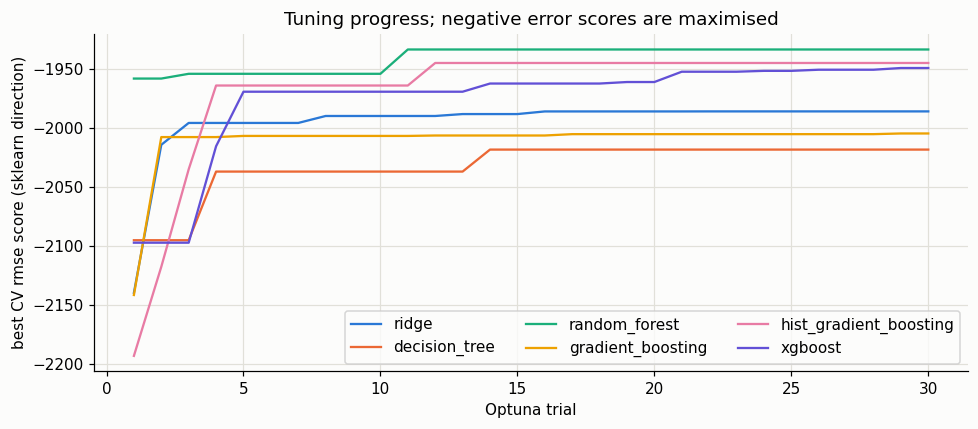

In [9]:
fig, ax = plt.subplots(figsize=(9,4))
for name,t in tuned.items():
    best_so_far = pd.Series([trial.value for trial in t["study"].trials]).cummax()
    ax.plot(np.arange(1,len(best_so_far)+1), best_so_far, label=name, color=MODEL_COLORS[name])
ax.set(xlabel="Optuna trial", ylabel=f"best CV {METRIC} score (sklearn direction)",
       title="Tuning progress; negative error scores are maximised")
ax.legend(ncol=3); plt.tight_layout(); plt.show()

Random Forest achieves the best nested cross-validation performance (RMSE ≈ €1,947.92), followed by Ridge (€1,987.90) and HistGradientBoosting (€1,998.96). However, hyperparameter tuning does not improve upon the untuned Random Forest baseline. Overall, Random Forest remains the strongest candidate, although the limited gains suggest that improving feature quality may be more valuable than further hyperparameter optimization.

# <font color='#2E86C1' size=6>**5. Comparing evaluation metrics**</font> <a class="anchor" id="comparison"></a>

Compare models on nested-CV scores, not the optimistic best-trial scores.

- **MAE (EUR):** average absolute error.
- **RMSE (EUR):** penalises large errors more strongly.
- **Median AE (EUR):** robust typical error.
- **R²:** variance explained relative to predicting the mean; may be negative.
- **Bias (EUR):** mean(predicted − actual); positive means over-prediction.

Error scores are negated by sklearn internally and converted back to positive EUR for display.

In [10]:
nested_results = {name: tuned[name]["nested"] for name in MODELS}
comparison = summary_table({**nested_results, **baseline_scores})

display(fmt(comparison))

best_by_metric = {
    metric: (
        comparison[metric].idxmin()
        if metric in LOWER_IS_BETTER
        else comparison[metric].idxmax()
    )
    for metric in SCORING
}
print("Best by metric:", best_by_metric)

if METRIC in LOWER_IS_BETTER:
    best_nested = comparison.loc[MODELS, METRIC].idxmin()
else:
    best_nested = comparison.loc[MODELS, METRIC].idxmax()

print(f"Best nested-CV model: {best_nested}")
print(f"Best nested-CV {METRIC}: {comparison.loc[best_nested, METRIC]:.3f}")

,rmse,mae,median_ae,r2,rmse_std,train_rmse,overfit_gap
model,,,,,,,
random_forest,1947.916,1260.479,774.732,0.330,226.187,1010.880,937.036
ridge,1987.897,1311.875,813.681,0.293,214.001,1550.979,436.918
hist_gradient_boosting,1998.962,1287.449,760.229,0.289,226.393,1253.086,745.876
xgboost,2041.285,1324.959,824.062,0.264,202.594,1287.566,753.718
gradient_boosting,2048.560,1313.455,811.004,0.253,237.471,1488.738,559.821
decision_tree,2068.582,1327.317,794.589,0.246,223.716,1613.828,454.754
dummy (training mean),2471.553,1637.982,1205.269,-0.050,237.755,1940.177,531.376


Best by metric: {'rmse': 'random_forest', 'mae': 'random_forest', 'median_ae': 'hist_gradient_boosting', 'r2': 'random_forest'}
Best nested-CV model: random_forest
Best nested-CV rmse: 1947.916


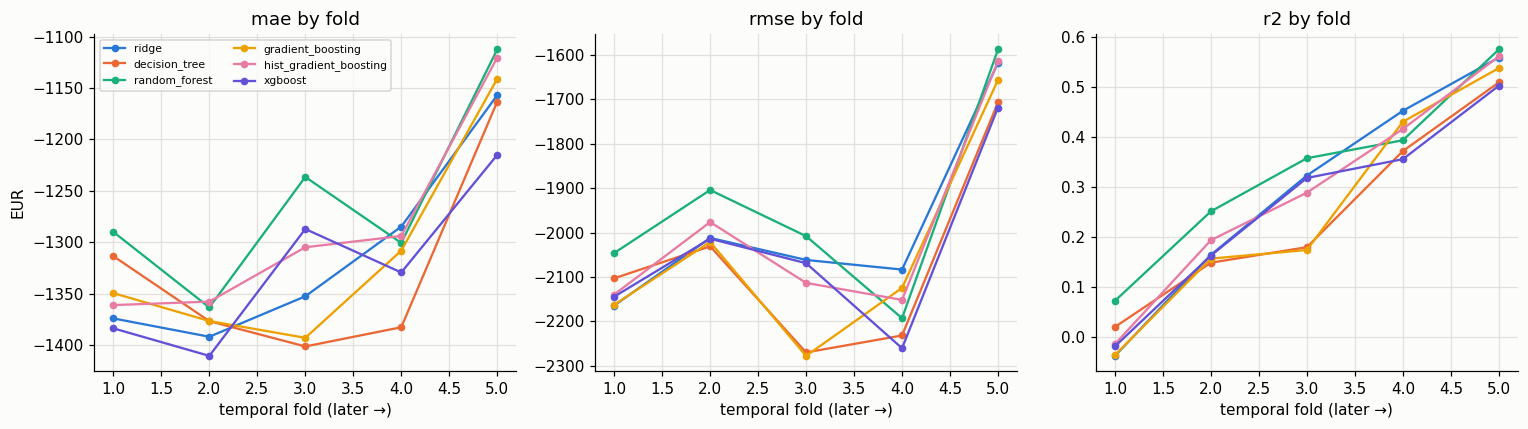

In [11]:
fig, axes = plt.subplots(1,3,figsize=(14,4))
for ax,metric in zip(axes,["mae","rmse","r2"]):
    for name in MODELS:
        vals = positive_scores(nested_results[name])[f"validation_{metric}"].to_numpy()
        ax.plot(np.arange(1,len(vals)+1),vals,marker="o",ms=4,label=name,color=MODEL_COLORS[name])
    ax.set(xlabel="temporal fold (later →)",title=f"{metric} by fold")
axes[0].set_ylabel("EUR"); axes[0].legend(fontsize=7,ncol=2)
plt.tight_layout(); plt.show()

# <font color='#2E86C1' size=6>**6. Final model and locked test set**</font> <a class="anchor" id="final"></a>

Choose using the configured selection metric and nested-CV results. Review paired fold differences, practical effect size and complexity before accepting the top-ranked model. Refit on all development rows. The locked test is evaluated only after selection; if its target is unavailable, generate predictions without reporting metrics.

In [12]:
FINAL = best_nested
print("Configured model:", CURRENT_MODEL, "| best nested-CV model:", best_nested)
print("Selected model:", FINAL, "| parameters:", tuned[FINAL]["study"].best_params)
final_pipeline = clone(tuned[FINAL]["best"]).fit(X_dev,y_dev)
oof_final = tuned[FINAL]["nested_oof"]
print(oof_report(y_dev,oof_final))

Configured model: random_forest | best nested-CV model: random_forest
Selected model: random_forest | parameters: {'model__n_estimators': 234, 'model__max_depth': 16, 'model__min_samples_leaf': 11, 'model__max_features': 1.0}
Out-of-fold predictions, development set (2215 rows, EUR):
  rmse: 1958.39   mae: 1260.48   median_ae: 766.50   r2: 0.3514   bias: -181.66
  spend: true mean 1983.07 / predicted mean 1801.40

Error by true-spend quartile:
                               rows      mae     bias
band                                                 
(1.2690000000000001, 331.025]   554   883.62   883.61
(331.025, 1076.72]              554   794.11   738.76
(1076.72, 2644.2]               556   716.15   123.63
(2644.2, 16248.26]              551  2657.56 -2486.25



In [13]:
p_test = predict_for_report(final_pipeline,X_test)
if y_test is not None and pd.Series(y_test).notna().all():
    print(holdout_report(y_test,p_test))
else:
    print("Test labels unavailable: generated predictions only; no holdout metrics.")
print("Prediction range (EUR):", float(np.min(p_test)), "to", float(np.max(p_test)))

Locked test set, evaluated once (685 rows, EUR):
  rmse: 2520.42   mae: 1285.92   median_ae: 654.31   r2: 0.4085   bias: -123.89
  spend: true mean 2199.23 / predicted mean 2075.34

Error by true-spend quartile:
                     rows      mae     bias
band                                       
(3.689, 381.03]       172   846.09   844.91
(381.03, 1053.62]     171   597.74   544.94
(1053.62, 2577.87]    171   628.06    81.20
(2577.87, 25654.33]   171  3074.36 -1972.28

Prediction range (EUR): 233.6110958533882 to 9086.822827564212


In [14]:
cv_final = positive_scores(tuned[FINAL]["nested"])
summary = {"nested CV MAE (EUR)":cv_final["validation_mae"].mean(),
           "nested CV RMSE (EUR)":cv_final["validation_rmse"].mean(),
           "nested CV R2":cv_final["validation_r2"].mean()}
if y_test is not None and pd.Series(y_test).notna().all():
    summary.update(regression_metrics(y_test,p_test))
pd.Series(summary).to_frame("value")

,value
nested CV MAE (EUR),-1260.478845
nested CV RMSE (EUR),-1947.915890
nested CV R2,0.330404
rmse,2520.415752
mae,1285.919592
median_ae,654.311200
r2,0.408524
bias,-123.892184


## Investigations

In [19]:
print("Target distribution — development:")
display(y_dev.describe(percentiles=[.5, .75, .90, .95, .99]).to_frame())

print("\nLargest development targets:")
display(y_dev.nlargest(10).to_frame("spend_next_90d"))

Target distribution — development:


,spend_next_90d
count,2659.000000
mean,1835.840519
std,2330.808370
min,1.270000
50%,958.600000
75%,2421.100000
90%,4835.866000
95%,6555.352000
99%,11225.943600
max,16248.260000



Largest development targets:


,spend_next_90d
2390,16248.26
1590,16165.89
2137,15655.29
315,15595.47
2432,15487.89
2065,14826.68
2495,14703.65
444,14198.97
326,14087.99
1459,13794.44


Development target skewness: 2.401040803809352


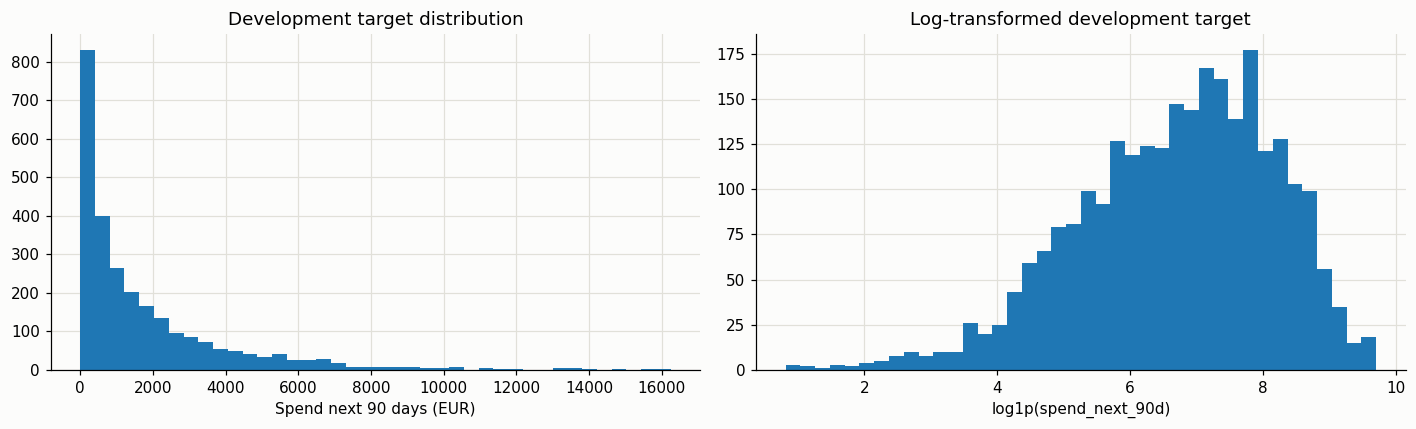

In [20]:
print("Development target skewness:", y_dev.skew())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(y_dev, bins=40)
axes[0].set_title("Development target distribution")
axes[0].set_xlabel("Spend next 90 days (EUR)")

axes[1].hist(np.log1p(y_dev), bins=40)
axes[1].set_title("Log-transformed development target")
axes[1].set_xlabel("log1p(spend_next_90d)")

plt.tight_layout()
plt.show()

## Experiment

In [23]:
# 5. Extract cross-validation fold scores
fold_scores_none = scores_none[0]
fold_scores_log = scores_log[0]

# 6. Compare temporal cross-validation results
comparison_log = summary_table({
    "Random Forest — original": fold_scores_none,
    "Random Forest — log1p": fold_scores_log
})

print("\nTEMPORAL CROSS-VALIDATION COMPARISON")
display(comparison_log)

# 7. Compare the main metrics
original = comparison_log.loc["Random Forest — original"]
log_model = comparison_log.loc["Random Forest — log1p"]

changes = pd.DataFrame({
    "Original target": original[["rmse", "mae", "median_ae", "r2"]],
    "Log1p target": log_model[["rmse", "mae", "median_ae", "r2"]]
})

changes["change (%)"] = (
    (changes["Log1p target"] - changes["Original target"])
    / changes["Original target"].abs()
    * 100
)

print("\nMETRIC COMPARISON")
display(changes.round(3))

# 8. Identify the winner by RMSE
winner = (
    "Random Forest — log1p"
    if log_model["rmse"] < original["rmse"]
    else "Random Forest — original"
)

print(f"\nBest model by temporal CV RMSE: {winner}")
print(f"Original RMSE: €{original['rmse']:.2f}")
print(f"Log1p RMSE:    €{log_model['rmse']:.2f}")

print("\nAll metrics are evaluated in EUR.")
print("Only development data was used.")


TEMPORAL CROSS-VALIDATION COMPARISON


,rmse,mae,median_ae,r2,rmse_std,train_rmse,overfit_gap
model,,,,,,,
Random Forest — original,1933.620459,1250.610420,783.251393,0.338839,170.569296,1206.127247,727.493212
Random Forest — log1p,2311.219081,1333.944871,610.782133,0.061773,251.588686,1409.401634,901.817447



METRIC COMPARISON


,Original target,Log1p target,change (%)
rmse,1933.620,2311.219,19.528
mae,1250.610,1333.945,6.664
median_ae,783.251,610.782,-22.020
r2,0.339,0.062,-81.769



Best model by temporal CV RMSE: Random Forest — original
Original RMSE: €1933.62
Log1p RMSE:    €2311.22

All metrics are evaluated in EUR.
Only development data was used.


1. Log1p makes overall prediction accuracy worse. RMSE increases by 19.5%, and MAE increases by 6.7%.

2. Log1p improves median error by 22%. It predicts the typical customer better, but sacrifices accuracy on larger spending amounts.

3. R² falls substantially. The original model explains around 34% of variation, compared with only 6% for the log-transformed model.

This is consistent with the log transformation reducing the influence of high-spending customers too much.

# <font color='#2E86C1' size=6>**7. Residual and spend-band analysis**</font> <a class="anchor" id="residuals"></a>

Overall metrics can hide systematic errors. Use nested out-of-fold predictions to inspect actual versus predicted spend, residuals, and error across actual-spend quartiles. These are development diagnostics; do not use locked-test results to revise model selection.

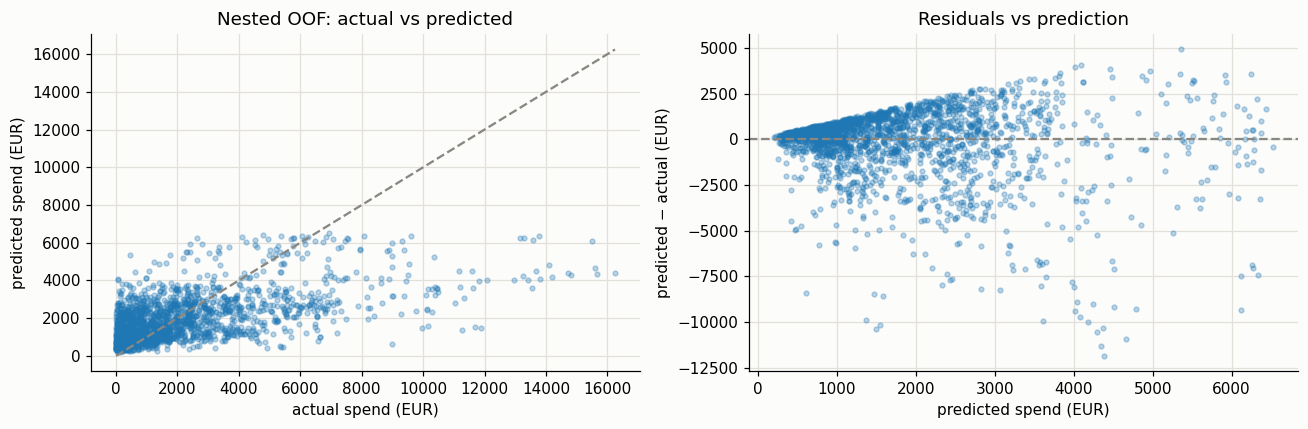

In [15]:
seen = pd.Series(oof_final).notna().to_numpy()
y_oof = y_dev.to_numpy()[seen]
p_oof = np.asarray(oof_final)[seen]
residual = p_oof-y_oof
fig,axes=plt.subplots(1,2,figsize=(12,4))
upper=max(float(np.max(y_oof)),float(np.max(p_oof)))
axes[0].scatter(y_oof,p_oof,s=10,alpha=.3); axes[0].plot([0,upper],[0,upper],"--",color=GREY)
axes[0].set(xlabel="actual spend (EUR)",ylabel="predicted spend (EUR)",title="Nested OOF: actual vs predicted")
axes[1].scatter(p_oof,residual,s=10,alpha=.3); axes[1].axhline(0,color=GREY,ls="--")
axes[1].set(xlabel="predicted spend (EUR)",ylabel="predicted − actual (EUR)",title="Residuals vs prediction")
plt.tight_layout(); plt.show()

,customers,true_mean_eur,predicted_mean_eur,mae_eur,bias_eur
band,,,,,
0,554,153.77,1037.38,883.62,883.61
1,554,650.96,1389.73,794.11,738.76
2,553,1773.31,1893.39,715.81,120.08
3,554,5353.85,2885.28,2647.39,-2468.57


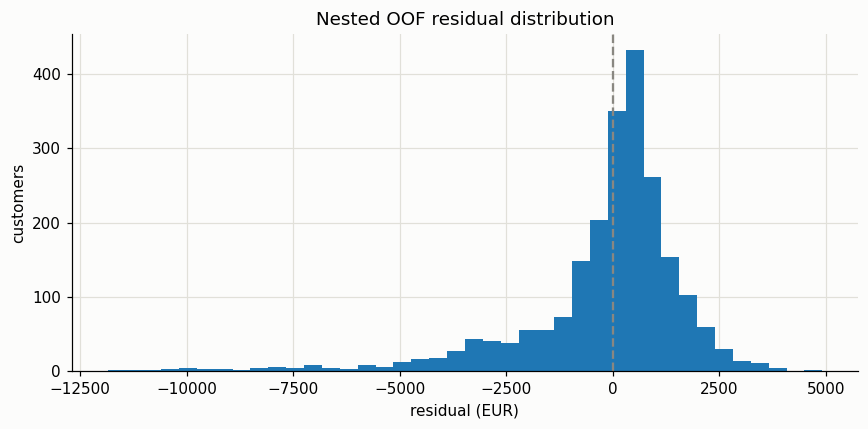

In [16]:
band = pd.qcut(pd.Series(y_oof).rank(method="first"),q=4,labels=False)
report = pd.DataFrame({"actual":y_oof,"predicted":p_oof,"band":band})
report["absolute_error"]=(report.predicted-report.actual).abs()
report["error"]=report.predicted-report.actual
display(report.groupby("band").agg(customers=("actual","size"),true_mean_eur=("actual","mean"),
    predicted_mean_eur=("predicted","mean"),mae_eur=("absolute_error","mean"),
    bias_eur=("error","mean")).round(2))
fig,ax=plt.subplots(figsize=(8,4)); ax.hist(residual,bins=40); ax.axvline(0,color=GREY,ls="--")
ax.set(xlabel="residual (EUR)",ylabel="customers",title="Nested OOF residual distribution")
plt.tight_layout(); plt.show()

# <font color='#2E86C1' size=6>**8. Feature importance**</font> <a class="anchor" id="importance"></a>

Permutation importance is measured on temporal validation folds using the increase in MAE when a raw input column is shuffled. This keeps importance in interpretable EUR units. Correlated columns can share signal, so single-column importance may understate a feature family.

In [17]:
perm_rows=[]
rng=np.random.default_rng(SEED)
for fold_id,(train_idx,valid_idx) in enumerate(folds):
    fitted=clone(tuned[FINAL]["best"]).fit(X_dev.iloc[train_idx],y_dev.iloc[train_idx])
    X_val,y_val=X_dev.iloc[valid_idx],y_dev.iloc[valid_idx]
    base=mean_absolute_error(y_val,predict_for_report(fitted,X_val))
    for col in X_dev.columns:
        shuffled=X_val.copy()
        shuffled[col]=rng.permutation(shuffled[col].to_numpy())
        score=mean_absolute_error(y_val,predict_for_report(fitted,shuffled))
        perm_rows.append({"feature":col,"fold":fold_id,"MAE increase (EUR)":score-base})
permutation=pd.DataFrame(perm_rows)
importance=permutation.groupby("feature")["MAE increase (EUR)"].agg(["mean","std","count"]).sort_values("mean",ascending=False)
display(importance.head(20).round(3))

MergeError: incompatible merge keys [0] dtype('int32') and Int32Dtype(), must be the same type

In [ ]:
top=importance.head(15).sort_values("mean")
fig,ax=plt.subplots(figsize=(8,5)); ax.barh(top.index,top["mean"],xerr=top["std"])
ax.axvline(0,color=GREY,lw=1)
ax.set(xlabel="increase in validation MAE when shuffled (EUR)",title=f"Permutation importance: {FINAL}")
plt.tight_layout(); plt.show()

# <font color='#2E86C1' size=6>**9. Drivers of customer spend**</font> <a class="anchor" id="drivers"></a>

Check how observed spend varies across feature bands for the most important numeric predictors. These are descriptive associations among returning customers, not causal effects.

In [ ]:
top_features=list(importance.head(6).index)
numeric_top=[c for c in top_features if pd.api.types.is_numeric_dtype(X_dev[c])]
if numeric_top:
    fig,axes=plt.subplots(1,len(numeric_top),figsize=(3.2*len(numeric_top),3.5))
    if len(numeric_top)==1: axes=[axes]
    for ax,col in zip(axes,numeric_top):
        values=pd.to_numeric(X_dev[col],errors="coerce")
        decile=pd.qcut(values.rank(method="first"),10,labels=False,duplicates="drop")
        grouped=pd.DataFrame({"value":values,"spend":y_dev,"decile":decile}).groupby("decile").agg(
            feature_median=("value","median"),mean_spend=("spend","mean"),n=("spend","size"))
        ax.plot(grouped.feature_median,grouped.mean_spend,marker="o")
        ax.set(title=col,xlabel="feature median",ylabel="mean spend (EUR)")
    plt.suptitle("Observed spend by feature decile (development)")
    plt.tight_layout(); plt.show()
else:
    print("No numeric features among the top permutation-importance columns.")

# <font color='#2E86C1' size=6>**10. Summary**</font> <a class="anchor" id="summary"></a>

Complete after a full notebook run.

- **Population:** returning customers with observed `spend_next_90d`; predictions are conditional on return.
- **Baseline:** record mean-prediction MAE and RMSE.
- **Best candidate:** record the best nested-CV model and MAE / RMSE / R².
- **Final selection:** explain whether the configured model was retained or replaced, using paired fold differences, effect size and complexity.
- **Locked test:** report EUR-scale metrics only if labels are available. Never use test results to tune.
- **Error pattern:** note whether high spenders are underpredicted or low spenders overpredicted.
- **Important drivers:** summarise stable permutation findings; associations are not causal.

**Limitations and next steps:** the model predicts spend conditional on a customer returning, not expected spend for every customer. A log1p target transform may help with a right-skewed target, but all metrics must be assessed after inverse transformation in EUR. Report MAE, median AE, RMSE, bias and spend-band errors together.